This project aims to determine which of the 1000 most popular IMDb movies — as rated by the general public — are also critically acclaimed. The core objective is to predict critical reception (as measured by MetaScore) using features related to public opinion (e.g., IMDb rating), cast/crew prestige, genre, and other metadata.

In [253]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression

imdb_raw = pd.read_csv('imdb_top_1000.csv')

ind_var = [
    # 'IMDB_Rating',
    'Meta_score']

In [254]:
imdb_raw_na_sum = imdb_raw.isna().sum()
imdb_raw_na_sum[imdb_raw_na_sum > 0]

Certificate    101
Meta_score     157
Gross          169
dtype: int64

### 🧹 Data Cleaning Steps ###

* **Certificate**: Entries with missing or unrated certificates were removed to ensure a consistent classification of audience type (e.g., U, PG-13, R).

* **Meta Score**: Rows with missing Meta_score were dropped, as this is our dependent variable in the analysis.

* **Gross**: The Gross column was cleaned by removing currency symbols and commas, and then converted to a float type for numeric analysis.

In [255]:
imdb_raw['Certificate'].value_counts()
imdb_raw = imdb_raw[(imdb_raw['Certificate'] != 'Unrated') & (~imdb_raw['Certificate'].isna())]

In [256]:
imdb_raw = imdb_raw[~imdb_raw['Meta_score'].isna()]

In [257]:
imdb_raw = imdb_raw[~imdb_raw['Gross'].isna()]

In [258]:
imdb_clean = imdb_raw.copy()
imdb_clean['Gross'] = imdb_clean['Gross'].str.replace(',','').astype(float)

imdb_clean.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,28341469.0
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,134966411.0
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,534858444.0
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,57300000.0
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,4360000.0


### 💰 Gross Revenue vs MetaScore ###
* I explored whether box office success (Gross) is a strong indicator of critical success. Initial findings show little to no correlation between high revenue and MetaScore, suggesting that commercial popularity doesn't necessarily equate to critical acclaim.

/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_12098/3634390428.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  imdb_clean.groupby(['Gross_Cat'])[ind_var].median().plot(kind='bar')


<Axes: xlabel='Gross_Cat'>

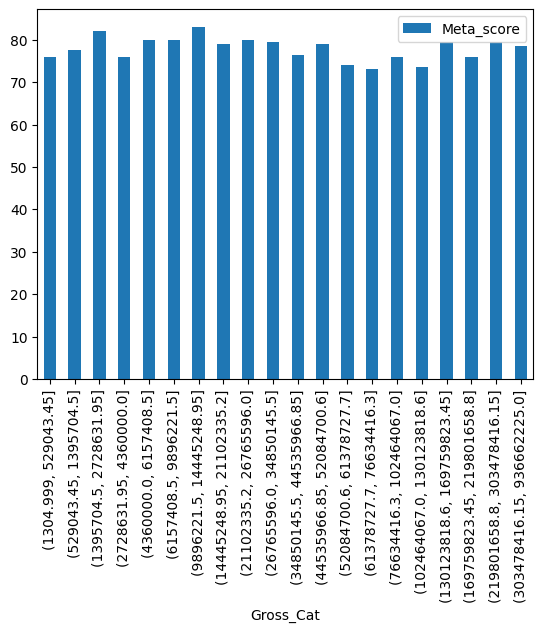

In [259]:
imdb_clean['Gross_Cat'] = pd.qcut(imdb_clean['Gross'], q=20)
imdb_clean.groupby(['Gross_Cat'])[ind_var].median().plot(kind='bar')

### 🏷️ Certificate Category Impact ###
* Certificate ratings were encoded into broad audience categories (e.g., "Mature", "Family", etc.).
Interestingly, films with general audience (U, PG) certificates tend to receive higher MetaScores, possibly due to broader accessibility or narrative clarity.

In [260]:
certificate_map = {
    'U': 'Kids',
    'G': 'Kids',
    'PG': 'Kids',
    'TV-PG': 'Kids',
    'Passed': 'Kids',
    'Approved': 'Kids',
    'GP': 'Kids',
    
    'UA': 'Teens',
    'U/A': 'Teens',
    'PG-13': 'Teens',
    'TV-14': 'Teens',
    
    'A': 'Mature',
    'R': 'Mature',
    '16': 'Mature',
    'TV-MA': 'Mature',
    
    'Unrated': 'Unrated'
}

imdb_clean['Certificate_cat'] = imdb_clean['Certificate'].map(certificate_map)
imdb_clean.groupby(['Certificate_cat'])[ind_var].median()

,Meta_score
Certificate_cat,
Kids,80.5
Mature,77.0
Teens,76.0


Evidence suggests that certificates labelled for Kids such that everyone can watch, tends to do better with critics

In [261]:
imdb_clean['For_all_flag'] = imdb_clean['Certificate_cat'] == 'Kids'

### 🌟 IMDb Rating vs MetaScore ###

* A clear positive trend is seen between IMDb scores and MetaScore. While not a perfect correlation, it suggests that general public perception aligns moderately with critical acclaim, especially for highly rated films.

In [262]:
imdb_clean['IMDB_Rating_Cat'] = pd.qcut(imdb_clean['IMDB_Rating'], q=2, labels=['High','Very High'])
imdb_clean['High_IMDB_Rating'] = imdb_clean['IMDB_Rating_Cat'].isin(['High'])
imdb_clean.groupby(['IMDB_Rating_Cat'])[ind_var].median()

/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_12098/3330149209.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  imdb_clean.groupby(['IMDB_Rating_Cat'])[ind_var].median()


,Meta_score
IMDB_Rating_Cat,
High,76.0
Very High,81.0


### 📈 Popularity and Runtime ###
* **Number of Votes**: Contrary to expectation, a high number of IMDb votes does not correlate with MetaScore — suggesting popularity alone is not a strong predictor of quality.

* **Runtime**: Movies with shorter durations tend to score slightly higher with critics, possibly due to tighter pacing or storytelling efficiency.

/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_12098/3775647766.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  imdb_clean.groupby('No_of_Votes_Cat')['Meta_score'].median().plot(kind='bar')


<Axes: xlabel='No_of_Votes_Cat'>

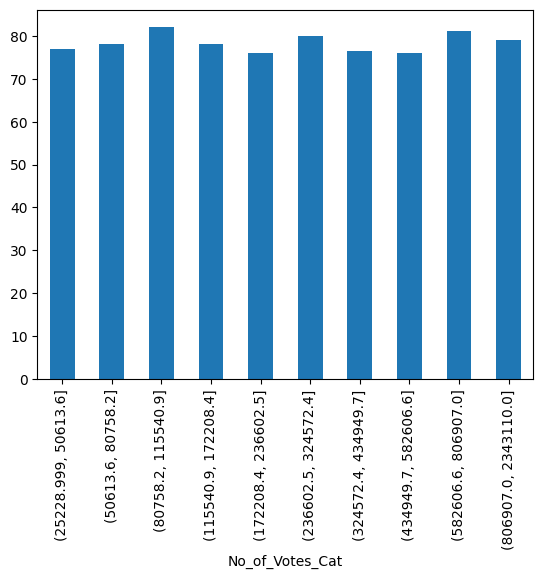

In [263]:
imdb_clean['No_of_Votes_Cat'] = pd.qcut(imdb_clean['No_of_Votes'], q=10)
imdb_clean.groupby('No_of_Votes_Cat')['Meta_score'].median().plot(kind='bar')

Number of votes seems to have little effect. Ie, well marketed content doesnt necessarily do better with critics

In [264]:
imdb_clean['Runtime_mins'] = imdb_clean['Runtime'].str.replace(' min', '').astype(float)
imdb_clean = imdb_clean.drop(columns=['Runtime'])

In [265]:
imdb_clean.loc[:,'Runtime_mins_cat'] = pd.qcut(imdb_clean['Runtime_mins'], q=4, labels=['Short', 'Medium-Short', 'Medium-Long', 'Long'])
imdb_clean.groupby('Runtime_mins_cat')[['Meta_score']].median()

/var/folders/8y/tt63y6sx2wv_8t3qwxp4gwwm0000gn/T/ipykernel_12098/881018580.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  imdb_clean.groupby('Runtime_mins_cat')[['Meta_score']].median()


,Meta_score
Runtime_mins_cat,
Short,80.0
Medium-Short,78.0
Medium-Long,76.0
Long,78.0


In [266]:
imdb_clean['Short_runtime_flag'] = imdb_clean['Runtime_mins_cat'] == 'Short'

### 🎬 Genre Effects ###
* Genre distribution was analyzed to understand thematic preferences among critics.

* Surprisingly, films tackling serious themes or belonging to traditionally dramatic genres often receive lower MetaScores than lighter, genre-blending movies.

* Comedic or family-genre films that incorporate 2–3 genres tend to perform best, suggesting genre diversity may be beneficial.

In [267]:
imdb_clean['Serious_themes'] = imdb_clean['Genre'].apply(lambda x : 
                          ('Drama' in x) |
                          ('Crime' in x) |
                          ('Action' in x) |
                          ('Thriller' in x) |
                          ('War' in x) |
                          ('Horror' in x) |
                          ('Film-Noir' in x))

imdb_clean.groupby('Serious_themes')[ind_var].median()

,Meta_score
Serious_themes,
False,81.0
True,77.0


In [268]:
imdb_clean['Genre'] = imdb_clean['Genre'].str.split(', ')
imdb_clean.loc[:,'Number_of_Genres'] = imdb_clean['Genre'].apply(len)
imdb_clean.groupby(['Serious_themes', 'Number_of_Genres'])[ind_var].agg(['median','size'])

Meta_score     
                                    median size
Serious_themes Number_of_Genres                
False          1                      77.5   16
               2                      77.0   13
               3                      83.0   57
True           1                      78.5   60
               2                      80.0  147
               3                      76.0  421

In [269]:
imdb_clean['Light_hearted_complex'] = (~imdb_clean['Serious_themes']) & (imdb_clean['Number_of_Genres'] == 3)

### 🌟 Star and Director Influence ###
* We labeled the top 100 most frequent actors as "famous" and counted how many appeared per film.

* Surprisingly, films with fewer famous actors often perform better with critics — perhaps due to more focus on storytelling or creative risk.

* Conversely, having a well-known director is positively correlated with critical success, suggesting directorial vision significantly impacts critical reception.

In [270]:
imdb_clean['List_of_stars'] = imdb_clean[[f'Star{i}' for i in range(1,5)]].apply(list,axis=1)
famous_stars = set(imdb_clean['List_of_stars'].explode().value_counts()[:100].keys())
# imdb_clean = imdb_clean.drop(columns=[c for c in imdb_clean.columns() if c.startswith('Star')])

imdb_clean['Number_of_famous_stars'] = imdb_clean['List_of_stars'].apply(lambda x : len(set(x).intersection(famous_stars)))
imdb_clean.groupby('Number_of_famous_stars')[ind_var].median()

,Meta_score
Number_of_famous_stars,
0,79.0
1,77.0
2,76.0
3,77.0
4,73.5


In [271]:
famous_director = set(imdb_clean['Director'].value_counts()[:30].keys())
imdb_clean['Famous_director'] = imdb_clean['Director'].isin(famous_director)
imdb_clean.groupby('Famous_director')[ind_var].median()

,Meta_score
Famous_director,
False,77.0
True,80.0


### 📅 Age Matters ###
* Older films — especially those released before the 1980s — tend to have consistently higher MetaScores, possibly due to legacy influence or enduring storytelling. This was captured using a Released_Decade variable

In [272]:
print(f'There are {sum(~imdb_clean['Released_Year'].apply(lambda x : str(x).isdigit()))} Released_Year values which are not a valid digit, thus removed.')
imdb_clean = imdb_clean[imdb_clean['Released_Year'].apply(lambda x : str(x).isdigit())]
imdb_clean.loc[:, 'Released_Year'] = imdb_clean['Released_Year'].astype(int)
imdb_clean.loc[:, 'Released_Decade'] = imdb_clean['Released_Year'] // 10 * 10

There are 1 Released_Year values which are not a valid digit, thus removed.


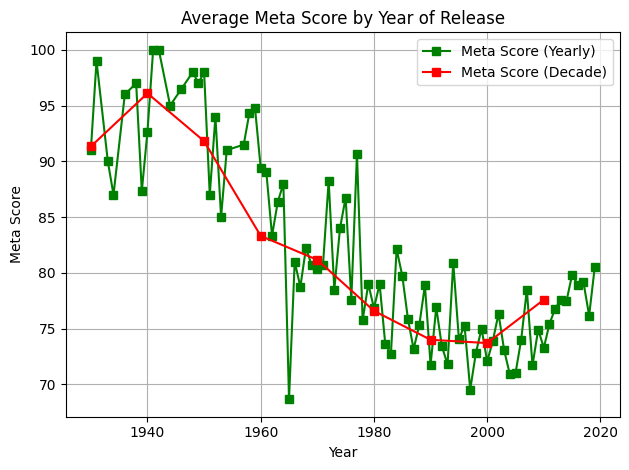

In [273]:
meta_yearly_avg = (
    imdb_clean.groupby('Released_Year')['Meta_score']
    .mean()
    .reset_index()
    .sort_values('Released_Year')
)

meta_decade_avg = (
    imdb_clean.groupby('Released_Decade')['Meta_score']
    .mean()
    .reset_index()
    .sort_values('Released_Decade')
)

plt.plot(meta_yearly_avg['Released_Year'], meta_yearly_avg['Meta_score'], marker='s', label='Meta Score (Yearly)', color='green')
plt.plot(meta_decade_avg['Released_Decade'], meta_decade_avg['Meta_score'], marker='s', label='Meta Score (Decade)', color='red')
plt.title('Average Meta Score by Year of Release')
plt.xlabel('Year')
plt.ylabel('Meta Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 📊 Building the model ###
* Combining the traits mentioned, we can use a Random Forest Classifier to build a model, predicting how these traits interact to predict the success of a respective movie.

In [274]:
imdb_clean = imdb_clean[[
    'Released_Decade', 
    'IMDB_Rating', 
    'Meta_score', 
    'Serious_themes', 
    'For_all_flag', 
    'Number_of_famous_stars',
    'Short_runtime_flag',
    'Light_hearted_complex',
    'Famous_director'
    ]]

In [275]:
meta_df = imdb_clean.copy()
meta_df['Meta_score'] = imdb_clean['Meta_score']/10
meta_df = meta_df[~meta_df['Meta_score'].isna()]
meta_df['Rating_classification'] = pd.qcut(meta_df['Meta_score'], q=2, labels=['Low','High'])
print(f'The threshold between High and Low is a meta score of {meta_df['Meta_score'].quantile(0.5)}')
meta_df = meta_df.drop(columns=['Meta_score'])

The threshold between High and Low is a meta score of 7.8


In [276]:
def train_model(df : pd.DataFrame, target : str):

    assert target in df.columns

    features = list(set(df.columns) - {target})

    X = df[features]
    y = df[target]

    le = LabelEncoder()
    y_encoded = le.fit_transform(y)  # Converts High, Med, Low to 0, 1, 2

    X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42)

    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, target_names=le.classes_))

    importances = model.feature_importances_
    feat_names = X.columns

    plt.figure(figsize=(8, 4))
    plt.barh(feat_names, importances)
    plt.title("Feature Importance (Random Forest)")
    plt.xlabel("Importance Score")
    plt.tight_layout()

    return model

    

A random forest classifier works by constructing lots of decision trees. Each tree is constructed using random criteria, subsetting the data into different buckets depending on the provided features. This is called bootstrapping. If the majority of trees label a movie as high, then the outcome is high.

### 🤔 Model Evaluation ###
* Using a subset of the data as test data, we can assess how successful the model is.

[[44 25]
 [26 48]]
              precision    recall  f1-score   support

        High       0.63      0.64      0.63        69
         Low       0.66      0.65      0.65        74

    accuracy                           0.64       143
   macro avg       0.64      0.64      0.64       143
weighted avg       0.64      0.64      0.64       143



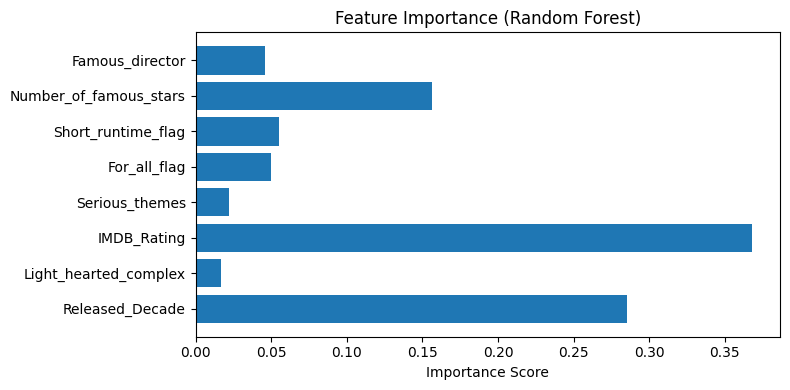

In [277]:
meta_model = train_model(meta_df, 'Rating_classification')
plt.show()

### 😵‍💫 Confusion Matrix: ###

* **True Positives (TP)** = 44: Movies that are actually High and were correctly predicted as High.

* **False Negatives (FN)** = 25: Movies that are actually High but predicted as Low.

* **False Positives (FP)** = 26: Movies that are actually Low but predicted as High.

* **True Negatives (TN)** = 48: Movies that are actually Low and correctly predicted as Low.

* **Precision** : The proportion of movies that were predicted to have a certain rating and did have that rating.
* **Recall** : Out of all movies of a certain rating, what proportion were picked up.
* **F1-Score** : Harmonic mean of Precision and Recall. Balance of the two.
* **Support** : How many movies actually belong to that set.

It can be said that out of all the movies that were predicted high, 63% were actually high and out of all the movies that were predicted low, 66% were actually low. Out of all high movies, 64% of them were picked up by the model. Similarly, 66% of movies predicted as low were actually low whilst 65% of all low movies were assigned as low by the model. The accuracy of the model is 64%, meaning 64% of movies were correctly assigned. An F1-score > 0.6 is better than the baseline.

### 🪵 Attempting Logisitic Regression ###

In [278]:
def train_logigistic_model(df : pd.DataFrame, target : str):

        features = list(set(df.columns) - {target})

        X = df[features]
        y = df[target]

        le = LabelEncoder()
        y_encoded = le.fit_transform(y)  # Converts High, Med, Low to 0, 1, 2

        X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42)

        model = LogisticRegression(max_iter=1000)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        print(confusion_matrix(y_test, y_pred))
        print(classification_report(y_test, y_pred, target_names=le.classes_))

        coeff_df = pd.DataFrame(model2.coef_, columns=X_train.columns)
        print(coeff_df)

        return model


In [279]:
model2 = train_logigistic_model(meta_df, 'Rating_classification')

[[40 29]
 [19 55]]
              precision    recall  f1-score   support

        High       0.68      0.58      0.62        69
         Low       0.65      0.74      0.70        74

    accuracy                           0.66       143
   macro avg       0.67      0.66      0.66       143
weighted avg       0.67      0.66      0.66       143

   Released_Decade  Light_hearted_complex  IMDB_Rating  Serious_themes  \
0         0.017998              -1.188646    -1.432114        -0.41476   

   For_all_flag  Short_runtime_flag  Number_of_famous_stars  Famous_director  
0       0.11352            -0.04326                0.233084        -0.294373  
